# 04 - Final evaluation on the held-out test set (one time only)

The 20% test split of GSE120584 (321 samples) has not been used for anything so far.
This notebook:

1. **Locks** the models, thresholds and metrics in a file *before* the test data is loaded.
2. Fits the final models on the **full training split** (re-tuning hyperparameters with 5-fold CV, training data only).
3. Chooses decision thresholds from **training** cross-validation predictions.
4. Loads the test set and evaluates **once**.

**Primary endpoint:** test AUC of the final model (LogReg + XGBoost + GradBoost ensemble, 817 ncRNAs + clinical).
**Secondary:** accuracy, balanced accuracy, sensitivity, specificity; AUC gain over the clinical baseline;
the 10-ncRNA panel. **Exploratory:** how the model scores DLB, VaD and MCI patients in the test set.

> Do not re-run this notebook after changing models. If anything changes, that is a new analysis and must be reported as such.

In [1]:
import os, sys, json, warnings
os.environ.setdefault("OMP_NUM_THREADS", "1")
sys.path.append("../src")
warnings.filterwarnings("ignore")
from datetime import datetime

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from utils import load_dataset, ROOT, FIGURES, SEED
from modeling import (BIG_GRIDS, CLINICAL, QUALITY, build_pipeline, detection_rate, make_features,
                      metrics, pick_threshold, bootstrap_auc_ci, bootstrap_auc_diff)

TAB = ROOT / "results" / "tables"; MOD = ROOT / "results" / "models"
FIG = FIGURES / "04_final_test"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
def savefig(n): plt.savefig(FIG / f"{n}.png", dpi=150, bbox_inches="tight")
COV = CLINICAL + QUALITY

## 1. Lock the analysis (before loading the test set)

In [2]:
ncrna = pd.read_csv(TAB / "01_eda_filtered_mirnas.csv")["miRNA"].tolist()
top10 = pd.read_csv(TAB / "03_top10_ncrnas.csv", index_col=0).index.tolist()

LOCK = MOD / "04_locked_config.json"
config = {
    "locked_at": datetime.now().isoformat(timespec="seconds"),
    "primary_endpoint": "test AUC, AD vs NC, model ENS(LogReg+XGB+GB) on 817 ncRNAs + age, sex, APOE4, detect_rate",
    "models": {
        "ENS(LogReg+XGB+GB)": "average probability of 3 pipelines, each tuned by 5-fold GridSearchCV on full training split (BIG_GRIDS, k in [100, 300, all])",
        "ENS(LogReg+XGB)": "same, 2 components (best accuracy in 02b)",
        "Panel10+clinical": "LogReg C=1 on top-10 ncRNAs from notebook 03 + covariates",
        "Clinical+quality": "LogReg C=1 on age, sex, APOE4, detect_rate (baseline A2)",
        "Clinical": "LogReg C=1 on age, sex, APOE4 (baseline A)",
    },
    "thresholds": "chosen on 5-fold training OOF predictions; rules: 'accuracy' and 'balanced'",
    "ncrna_features": len(ncrna), "top10": top10,
}
if LOCK.exists():
    print("Lock file already exists (test set was evaluated before):"); print(LOCK.read_text())
else:
    LOCK.write_text(json.dumps(config, indent=2)); print(json.dumps(config, indent=2))

{
  "locked_at": "2026-11-16T15:58:16",
  "primary_endpoint": "test AUC, AD vs NC, model ENS(LogReg+XGB+GB) on 817 ncRNAs + age, sex, APOE4, detect_rate",
  "models": {
    "ENS(LogReg+XGB+GB)": "average probability of 3 pipelines, each tuned by 5-fold GridSearchCV on full training split (BIG_GRIDS, k in [100, 300, all])",
    "ENS(LogReg+XGB)": "same, 2 components (best accuracy in 02b)",
    "Panel10+clinical": "LogReg C=1 on top-10 ncRNAs from notebook 03 + covariates",
    "Clinical+quality": "LogReg C=1 on age, sex, APOE4, detect_rate (baseline A2)",
    "Clinical": "LogReg C=1 on age, sex, APOE4 (baseline A)"
  },
  "thresholds": "chosen on 5-fold training OOF predictions; rules: 'accuracy' and 'balanced'",
  "ncrna_features": 817,
  "top10": [
    "hsa-miR-128-1-5p",
    "hsa-miR-3917",
    "hsa-miR-4667-5p",
    "hsa-miR-1471",
    "hsa-miR-6861-5p",
    "hsa-miR-3122",
    "hsa-miR-6743-5p",
    "hsa-miR-3689d",
    "hsa-miR-6840-3p",
    "hsa-miR-6784-5p"
  ]
}


## 2. Fit final models on the full training split

In [3]:
X, clin = load_dataset("GSE120584_serum", split="train", diagnoses=["AD", "NC"])
clin["detect_rate"] = detection_rate(X)
F = make_features(X[ncrna], clin)
y = (clin["diagnosis"] == "AD").astype(int)
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
print(f"Training: {len(y)} samples (AD {y.sum()}, NC {(1-y).sum()})")

Training: 1046 samples (AD 816, NC 230)


In [4]:
cache = MOD / "04_final_models.joblib"
if cache.exists():
    final = joblib.load(cache); print("Loaded fitted models from cache")
else:
    final = {}
    spw = (y == 0).sum() / (y == 1).sum()
    cols = ncrna + COV
    for algo in ["LogReg", "XGBoost", "GradBoost"]:
        make, grid = BIG_GRIDS[algo]
        pipe = build_pipeline(make(spw), ncrna, COV)
        grid = {**grid, "features__ncrna__select__k": [100, 300, "all"]}
        gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv5, n_jobs=-1).fit(F[cols], y)
        oof = cross_val_predict(clone(gs.best_estimator_), F[cols], y, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]
        final[algo] = {"model": gs.best_estimator_, "cols": cols, "params": gs.best_params_,
                       "cv_auc": gs.best_score_, "train_oof": pd.Series(oof, index=y.index)}
        print(f"{algo:10s} best CV AUC {gs.best_score_:.3f}  {gs.best_params_}")
    for name, cols in [("Panel10+clinical", top10 + COV), ("Clinical+quality", COV), ("Clinical", CLINICAL)]:
        m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))
        oof = cross_val_predict(m, F[cols], y, cv=cv5, method="predict_proba")[:, 1]
        final[name] = {"model": m.fit(F[cols], y), "cols": cols, "train_oof": pd.Series(oof, index=y.index)}
        print(f"{name:18s} training CV AUC {roc_auc_score(y, oof):.3f}")
    joblib.dump(final, cache)

ENSEMBLES = {"ENS(LogReg+XGB+GB)": ["LogReg", "XGBoost", "GradBoost"], "ENS(LogReg+XGB)": ["LogReg", "XGBoost"]}
SINGLE = ["Panel10+clinical", "Clinical+quality", "Clinical"]

def train_oof(name):
    if name in ENSEMBLES: return pd.concat([final[c]["train_oof"] for c in ENSEMBLES[name]], axis=1).mean(axis=1)
    return final[name]["train_oof"]

thresholds = {n: {r: pick_threshold(y, train_oof(n), r) for r in ["accuracy", "balanced"]}
              for n in list(ENSEMBLES) + SINGLE}
pd.DataFrame(thresholds).T.round(3)

LogReg     best CV AUC 0.904  {'clf__C': 0.1, 'clf__l1_ratio': 1.0, 'features__ncrna__select__k': 'all'}


XGBoost    best CV AUC 0.915  {'clf__learning_rate': 0.03, 'clf__max_depth': 4, 'clf__n_estimators': 600, 'features__ncrna__select__k': 'all'}


GradBoost  best CV AUC 0.903  {'clf__l2_regularization': 1.0, 'clf__learning_rate': 0.1, 'clf__max_depth': None, 'features__ncrna__select__k': 'all'}
Panel10+clinical   training CV AUC 0.893
Clinical+quality   training CV AUC 0.837
Clinical           training CV AUC 0.832


,accuracy,balanced
ENS(LogReg+XGB+GB),0.466,0.706
ENS(LogReg+XGB),0.444,0.580
Panel10+clinical,0.206,0.512
Clinical+quality,0.264,0.469
Clinical,0.278,0.415


## 3. Load the test set and evaluate (once)

In [5]:
Xt_all, clin_t_all = load_dataset("GSE120584_serum", split="test")
assert not set(Xt_all.index) & set(X.index), "test and training samples overlap!"
clin_t_all["detect_rate"] = detection_rate(Xt_all)
Ft_all = make_features(Xt_all[ncrna], clin_t_all)
print(clin_t_all["diagnosis"].value_counts().to_string())

mask = clin_t_all["diagnosis"].isin(["AD", "NC"])
Ft, yt = Ft_all[mask], (clin_t_all.loc[mask, "diagnosis"] == "AD").astype(int)
print(f"\nPrimary test set (AD vs NC): {len(yt)} samples (AD {yt.sum()}, NC {(1-yt).sum()}); 'always AD' accuracy = {yt.mean():.3f}")

def predict(name, Fx):
    if name in ENSEMBLES:
        return np.mean([final[c]["model"].predict_proba(Fx[final[c]["cols"]])[:, 1] for c in ENSEMBLES[name]], axis=0)
    return final[name]["model"].predict_proba(Fx[final[name]["cols"]])[:, 1]

test_scores = {n: pd.Series(predict(n, Ft), index=yt.index) for n in thresholds}

diagnosis
AD     205
NC      58
DLB     34
VaD     18
MCI      6

Primary test set (AD vs NC): 263 samples (AD 205, NC 58); 'always AD' accuracy = 0.779


In [6]:
rows = []
for n, s in test_scores.items():
    lo, hi = bootstrap_auc_ci(yt, s, n=2000)
    r = {"model": n, "test_AUC": roc_auc_score(yt, s), "AUC_95CI": f"{lo:.3f}-{hi:.3f}",
         "train_CV_AUC": roc_auc_score(y, train_oof(n))}
    for rule in ["accuracy", "balanced"]:
        m = metrics(yt, s, (s >= thresholds[n][rule]).astype(int))
        for k in ["accuracy", "balanced_acc", "sensitivity", "specificity"]:
            r[f"{rule[:3]}_{k}"] = m[k]
    rows.append(r)
test_res = pd.DataFrame(rows)
test_res.to_csv(TAB / "04_test_results.csv", index=False)
test_res.round(3)

,model,test_AUC,AUC_95CI,train_CV_AUC,acc_accuracy,acc_balanced_acc,acc_sensitivity,acc_specificity,bal_accuracy,bal_balanced_acc,bal_sensitivity,bal_specificity
0,ENS(LogReg+XGB+GB),0.934,0.889-0.972,0.916,0.913,0.826,0.980,0.672,0.878,0.866,0.888,0.845
1,ENS(LogReg+XGB),0.934,0.890-0.972,0.916,0.913,0.839,0.971,0.707,0.913,0.876,0.941,0.810
2,Panel10+clinical,0.902,0.850-0.949,0.893,0.886,0.785,0.966,0.603,0.844,0.820,0.863,0.776
3,Clinical+quality,0.905,0.853-0.945,0.837,0.878,0.767,0.966,0.569,0.852,0.831,0.868,0.793
4,Clinical,0.889,0.831-0.934,0.832,0.871,0.769,0.951,0.586,0.871,0.843,0.893,0.793


In [7]:
gains = []
for n in ["ENS(LogReg+XGB+GB)", "ENS(LogReg+XGB)", "Panel10+clinical"]:
    for base in ["Clinical", "Clinical+quality"]:
        d, lo, hi, p = bootstrap_auc_diff(yt, test_scores[base], test_scores[n], n=2000)
        gains.append({"model": n, "vs": base, "AUC_gain": d, "CI_low": lo, "CI_high": hi, "p_one_sided": p})
pd.DataFrame(gains).to_csv(TAB / "04_test_gains.csv", index=False)
pd.DataFrame(gains).round(3)

,model,vs,AUC_gain,CI_low,CI_high,p_one_sided
0,ENS(LogReg+XGB+GB),Clinical,0.046,0.005,0.094,0.016
1,ENS(LogReg+XGB+GB),Clinical+quality,0.030,-0.009,0.072,0.070
2,ENS(LogReg+XGB),Clinical,0.046,0.004,0.095,0.015
3,ENS(LogReg+XGB),Clinical+quality,0.030,-0.009,0.074,0.068
4,Panel10+clinical,Clinical,0.013,-0.027,0.052,0.257
5,Panel10+clinical,Clinical+quality,-0.003,-0.042,0.033,0.535


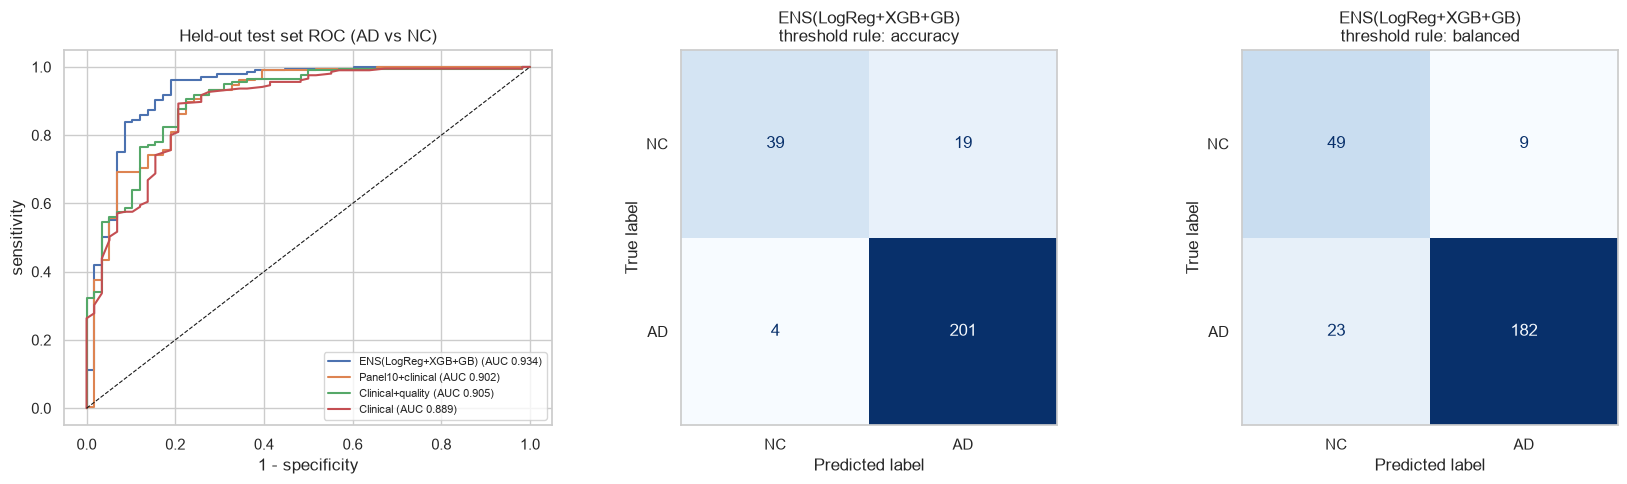

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for n in ["ENS(LogReg+XGB+GB)", "Panel10+clinical", "Clinical+quality", "Clinical"]:
    fpr, tpr, _ = roc_curve(yt, test_scores[n])
    axes[0].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(yt, test_scores[n]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=.8); axes[0].legend(fontsize=8, loc="lower right")
axes[0].set_xlabel("1 - specificity"); axes[0].set_ylabel("sensitivity"); axes[0].set_title("Held-out test set ROC (AD vs NC)")
n = "ENS(LogReg+XGB+GB)"
for ax, rule in zip(axes[1:], ["accuracy", "balanced"]):
    pred = (test_scores[n] >= thresholds[n][rule]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(yt, pred), display_labels=["NC", "AD"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{n}\nthreshold rule: {rule}"); ax.grid(False)
plt.tight_layout(); savefig("test_roc_confusion"); plt.show()

## 4. Exploratory: other dementias and MCI in the test set

The model was trained on AD vs NC only. How does it score DLB, VaD and MCI patients?
If it calls most DLB/VaD patients "AD", the signature reflects **dementia in general** rather than AD specifically.

In [9]:
n = "ENS(LogReg+XGB+GB)"
s_all = pd.Series(predict(n, Ft_all), index=Ft_all.index)
t = thresholds[n]["balanced"]
expl = (clin_t_all.assign(score=s_all, called_AD=(s_all >= t))
        .groupby("diagnosis").agg(n=("score", "size"), mean_score=("score", "mean"), pct_called_AD=("called_AD", "mean")))
expl["pct_called_AD"] = (100 * expl["pct_called_AD"]).round(1)
print("Using the balanced threshold:")
expl.reindex(["NC", "MCI", "AD", "DLB", "VaD"]).round(3)

Using the balanced threshold:


,n,mean_score,pct_called_AD
diagnosis,,,
NC,58,0.322,15.5
MCI,6,0.832,83.3
AD,205,0.884,88.8
DLB,34,0.857,88.2
VaD,18,0.896,88.9


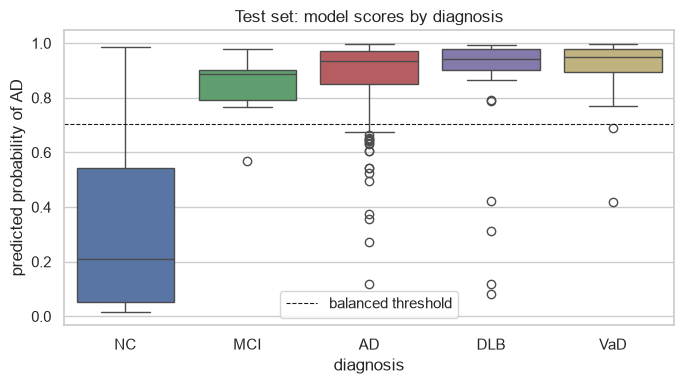

In [10]:
plt.figure(figsize=(7, 4))
order = ["NC", "MCI", "AD", "DLB", "VaD"]
sns.boxplot(x=clin_t_all["diagnosis"], y=s_all, order=order, hue=clin_t_all["diagnosis"], legend=False,
            palette={"NC": "#4C72B0", "MCI": "#55A868", "AD": "#C44E52", "DLB": "#8172B2", "VaD": "#CCB974"})
plt.axhline(t, ls="--", c="k", lw=.8, label="balanced threshold"); plt.legend()
plt.ylabel("predicted probability of AD"); plt.title("Test set: model scores by diagnosis")
plt.tight_layout(); savefig("test_scores_by_diagnosis"); plt.show()

## 5. Findings to record (fill in)

- Test AUC of the final model (95% CI) vs training CV AUC (any drop = optimism):
- Accuracy (accuracy threshold) / balanced accuracy (balanced threshold):
- AUC gain over clinical baseline on the test set:
- 10-ncRNA panel test AUC:
- DLB / VaD: called AD how often? (AD-specific or general dementia signal?)
- MCI (n is very small here; see notebook 05 for GSE215789):